In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual básica
plt.style.use('ggplot')
sns.set_theme(style="whitegrid")

# Usamos read_csv porque el archivo internamente está separado por comas
ruta_archivo = r"bodyfat.xls"
df = pd.read_csv(ruta_archivo)

print("¡Archivo cargado con éxito!")
display(df.head())

¡Archivo cargado con éxito!


,Density,BodyFat,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,1.0708,12.3,23,154.25,67.75,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,1.0853,6.1,22,173.25,72.25,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,1.0414,25.3,22,154.00,66.25,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,1.0751,10.4,26,184.75,72.25,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,1.0340,28.7,24,184.25,71.25,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7


In [10]:
print("\n--- Información del Dataset (Tipos de variables) ---")
df.info()

print("\n--- Cantidad de Valores Nulos ---")
print(df.isnull().sum())


--- Información del Dataset (Tipos de variables) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 252 entries, 0 to 251
Data columns (total 15 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Density  252 non-null    float64
 1   BodyFat  252 non-null    float64
 2   Age      252 non-null    int64  
 3   Weight   252 non-null    float64
 4   Height   252 non-null    float64
 5   Neck     252 non-null    float64
 6   Chest    252 non-null    float64
 7   Abdomen  252 non-null    float64
 8   Hip      252 non-null    float64
 9   Thigh    252 non-null    float64
 10  Knee     252 non-null    float64
 11  Ankle    252 non-null    float64
 12  Biceps   252 non-null    float64
 13  Forearm  252 non-null    float64
 14  Wrist    252 non-null    float64
dtypes: float64(14), int64(1)
memory usage: 29.7 KB

--- Cantidad de Valores Nulos ---
Density    0
BodyFat    0
Age        0
Weight     0
Height     0
Neck       0
Chest      0
Abdomen    0
Hip 

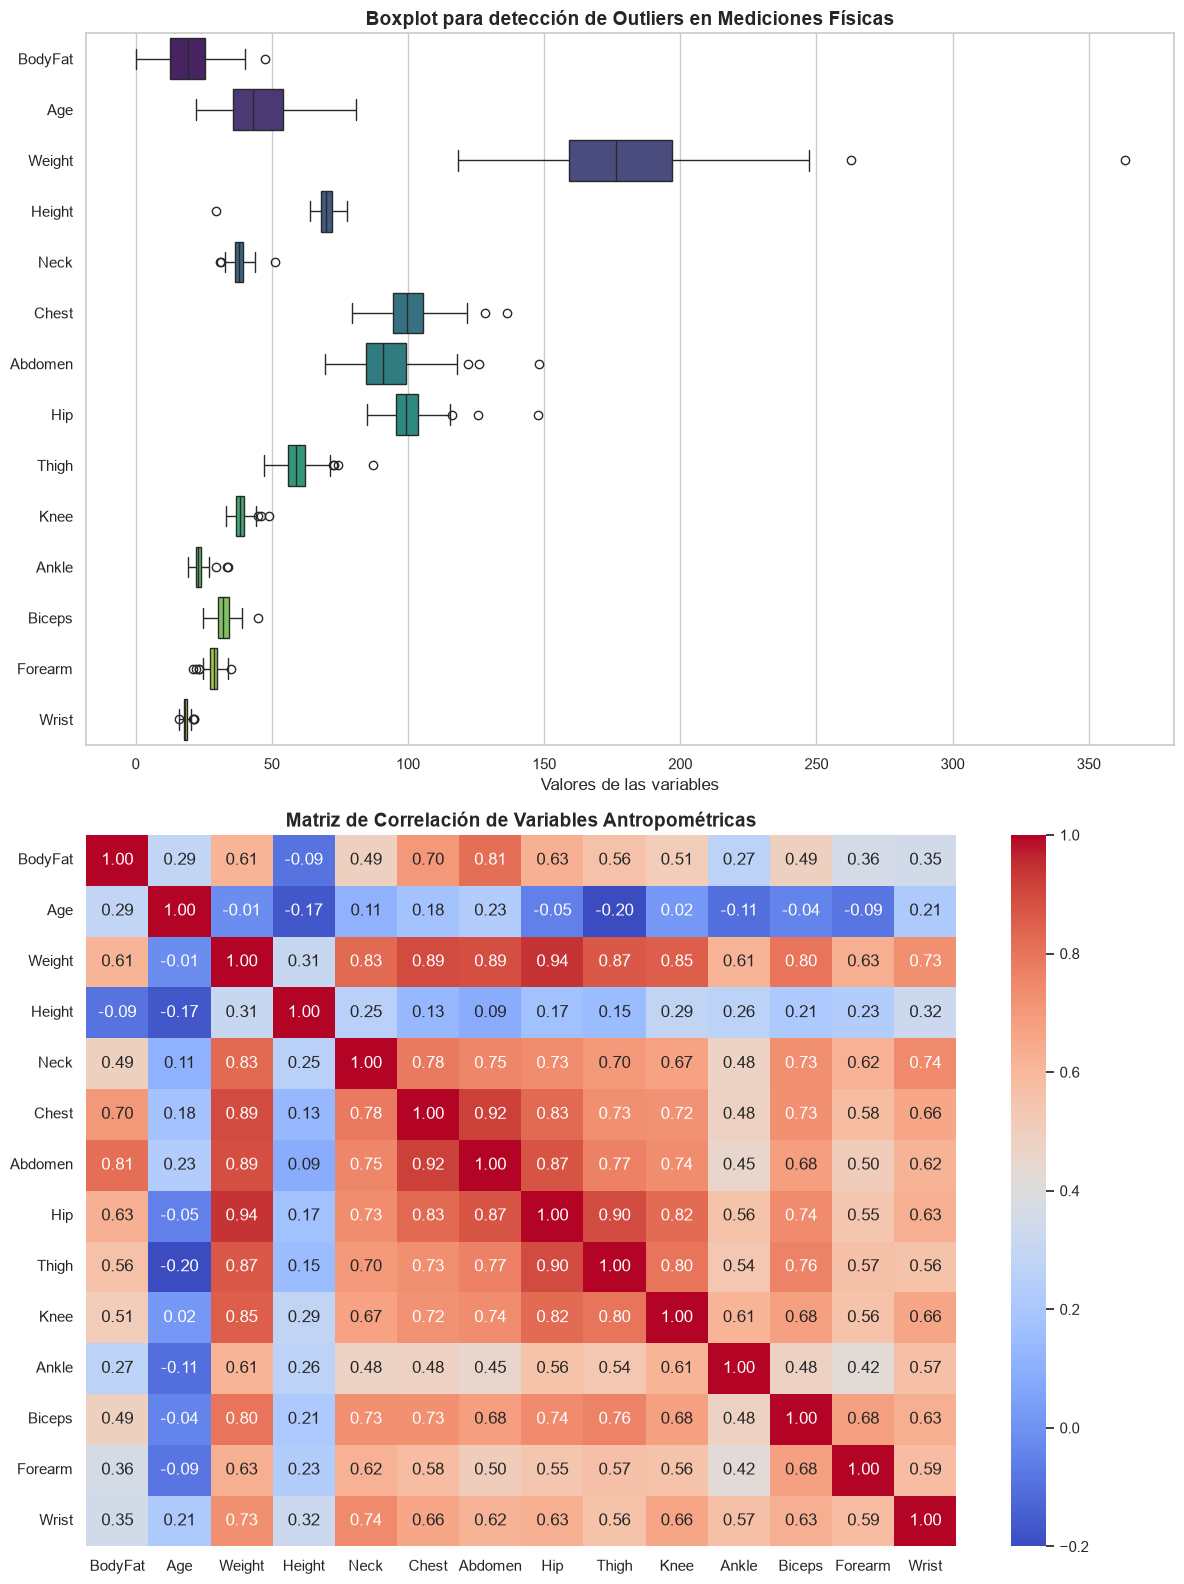

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Eliminar la variable Density para evitar fuga de datos
df = df.drop(columns=['Density'], errors='ignore')

# 2. Configurar la figura con dos subgráficos
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# 3. Diagrama de Caja (Boxplot) para detectar outliers
# Normalizamos temporalmente las escalas para ver todas las variables juntas
sns.boxplot(data=df, orient="h", ax=axes[0], palette="viridis")
axes[0].set_title("Boxplot para detección de Outliers en Mediciones Físicas", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Valores de las variables")

# 4. Mapa de Calor (Heatmap) de correlaciones
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Matriz de Correlación de Variables Antropométricas", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [12]:
%pip install scikit-learn
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Usamos el DataFrame original con todos los outliers
df_full = df.copy()

# 2. Conversiones y cálculo de IMC
df_full['Weight_kg'] = df_full['Weight'] * 0.453592
df_full['Height_m'] = df_full['Height'] * 0.0254
df_full['IMC'] = df_full['Weight_kg'] / (df_full['Height_m'] ** 2)

# 3. Predicción ingenua (Fórmula de Deurenberg)
df_full['BodyFat_IMC_Pred'] = (1.20 * df_full['IMC']) + (0.23 * df_full['Age']) - 16.2

# 4. Cálculo de métricas
mae_full = mean_absolute_error(df_full['BodyFat'], df_full['BodyFat_IMC_Pred'])
rmse_full = np.sqrt(mean_squared_error(df_full['BodyFat'], df_full['BodyFat_IMC_Pred']))

print("--- RESULTADOS DEL BENCHMARK (Con Outliers) ---")
print(f"MAE Completo: {mae_full:.2f} %")
print(f"RMSE Completo: {rmse_full:.2f} %")

# 5. Visualizar el paciente atípico que causa la distorsión
outlier = df_full[df_full['Height'] < 30][['Age', 'Weight', 'Height', 'BodyFat', 'IMC', 'BodyFat_IMC_Pred']]
print("\n--- Paciente Atípico (Error de medición) ---")
display(outlier)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
--- RESULTADOS DEL BENCHMARK (Con Outliers) ---
MAE Completo: 7.11 %
RMSE Completo: 12.80 %

--- Paciente Atípico (Error de medición) ---



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,Age,Weight,Height,BodyFat,IMC,BodyFat_IMC_Pred
41,44,205.0,29.5,32.9,165.618094,192.661713


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Filtramos los outliers biológicamente imposibles que descubriste en tu EDA
df_clean = df[(df['Height'] > 30) & (df['BodyFat'] > 0)].copy()

# 2. Conversiones al sistema métrico
df_clean['Weight_kg'] = df_clean['Weight'] * 0.453592
df_clean['Height_m'] = df_clean['Height'] * 0.0254

# 3. Cálculo del Índice de Masa Corporal (IMC)
df_clean['IMC'] = df_clean['Weight_kg'] / (df_clean['Height_m'] ** 2)

# 4. Predicción ingenua (Benchmark) mediante fórmula de Deurenberg para hombres
# Fórmula: (1.20 x IMC) + (0.23 x Edad) - (10.8 x 1[por ser hombre]) - 5.4
df_clean['BodyFat_IMC_Pred'] = (1.20 * df_clean['IMC']) + (0.23 * df_clean['Age']) - 16.2

# 5. Evaluación de las Métricas
mae_benchmark = mean_absolute_error(df_clean['BodyFat'], df_clean['BodyFat_IMC_Pred'])
rmse_benchmark = np.sqrt(mean_squared_error(df_clean['BodyFat'], df_clean['BodyFat_IMC_Pred']))

print("--- RESULTADOS DEL BENCHMARK (Modelo Base) ---")
print(f"Error Absoluto Medio (MAE) sin outliers: {mae_benchmark:.2f} % de grasa")
print(f"Raíz del Error Cuadrático Medio (RMSE) sin outliers: {rmse_benchmark:.2f} % de grasa")

--- RESULTADOS DEL BENCHMARK (Modelo Base) ---
Error Absoluto Medio (MAE) sin outliers: 6.47 % de grasa
Raíz del Error Cuadrático Medio (RMSE) sin outliers: 7.89 % de grasa


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold

# 1. Aseguramos el dataset limpio (sin Density y sin outliers extremos)
df_clean = df[(df['Height'] > 30) & (df['BodyFat'] > 0)].copy()
df_clean = df_clean.drop(columns=['Density'], errors='ignore')

# 2. Separar Variable Objetivo (y) y Variables Predictoras (X)
X = df_clean.drop(columns=['BodyFat'])
y = df_clean['BodyFat']

# 3. Configurar Validación Cruzada (5 folds)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 4. Instanciar el modelo de Regresión Lineal Múltiple
modelo_rl = LinearRegression()

print("Datos y modelo configurados correctamente para Validación Cruzada.")

Datos y modelo configurados correctamente para Validación Cruzada.


In [15]:
# 1. Ejecutar Cross-Validation extrayendo MAE y RMSE
scores = cross_validate(modelo_rl, X, y, cv=kf, 
                        scoring=('neg_mean_absolute_error', 'neg_root_mean_squared_error'))

mae_cv = -scores['test_neg_mean_absolute_error'].mean()
rmse_cv = -scores['test_neg_root_mean_squared_error'].mean()

print("--- RESULTADOS REGRESIÓN LINEAL MÚLTIPLE (CROSS-VALIDATION) ---")
print(f"MAE Promedio: {mae_cv:.2f} % de grasa")
print(f"RMSE Promedio: {rmse_cv:.2f} % de grasa\n")

# 2. Entrenar en todo el set limpio para ver el peso de cada variable (Coeficientes)
modelo_rl.fit(X, y)
coeficientes = pd.Series(modelo_rl.coef_, index=X.columns).sort_values(ascending=False)

print("--- IMPACTO DE LAS VARIABLES EN LA PREDICCIÓN (Coeficientes) ---")
display(coeficientes)

--- RESULTADOS REGRESIÓN LINEAL MÚLTIPLE (CROSS-VALIDATION) ---
MAE Promedio: 3.70 % de grasa
RMSE Promedio: 4.56 % de grasa

--- IMPACTO DE LAS VARIABLES EN LA PREDICCIÓN (Coeficientes) ---


Abdomen    0.959373
Forearm    0.439071
Thigh      0.222455
Biceps     0.195123
Ankle      0.166608
Age        0.061045
Knee       0.006830
Chest     -0.034495
Height    -0.060762
Weight    -0.086515
Hip       -0.209241
Neck      -0.461806
Wrist     -1.631857
dtype: float64

In [17]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate, KFold

# 1. Recuperar los datos limpios (sin Density y sin valores atípicos biológicamente imposibles)
# Ajusta la ruta si es necesario para tu entorno local
ruta_archivo = r"bodyfat.xls"
df = pd.read_csv(ruta_archivo)

df_clean = df[(df['Height'] > 30) & (df['BodyFat'] > 0)].copy()
df_clean = df_clean.drop(columns=['Density'], errors='ignore')

# 2. Separar Variable Objetivo (y) y Variables Predictoras (X)
X = df_clean.drop(columns=['BodyFat'])
y = df_clean['BodyFat']

# 3. Configurar Validación Cruzada K-Fold (5 particiones aleatorias)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 4. Diccionario de Modelos a evaluar
modelos = {
    'Regresión Lineal Múltiple': LinearRegression(),
    'Ridge (L2)': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'Lasso (L1)': make_pipeline(StandardScaler(), Lasso(alpha=0.1)),
    'ElasticNet': make_pipeline(StandardScaler(), ElasticNet(alpha=0.1, l1_ratio=0.5)),
    'Random Forest (Ensamble)': RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
    'Gradient Boosting (Ensamble)': GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42),
    'SVR': make_pipeline(StandardScaler(), SVR(C=1.0, kernel='rbf'))
}

# 5. Ejecutar la validación cruzada y almacenar resultados
resultados = []
for nombre, modelo in modelos.items():
    scores = cross_validate(modelo, X, y, cv=kf, 
                            scoring=('neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'))
    resultados.append({
        'Modelo': nombre,
        'MAE (%)': -scores['test_neg_mean_absolute_error'].mean(),
        'RMSE': -scores['test_neg_root_mean_squared_error'].mean(),
        'R2': scores['test_r2'].mean()
    })

# 6. Mostrar tabla ordenada por el menor Error Absoluto Medio (MAE)
df_res = pd.DataFrame(resultados).sort_values(by='MAE (%)')
print("--- COMPARATIVA DE MODELOS (CROSS-VALIDATION) ---")
display(df_res)

--- COMPARATIVA DE MODELOS (CROSS-VALIDATION) ---


,Modelo,MAE (%),RMSE,R2
1,Ridge (L2),3.685224,4.571110,0.682936
0,Regresión Lineal Múltiple,3.695963,4.564803,0.684119
2,Lasso (L1),3.696604,4.591688,0.677493
3,ElasticNet,3.770091,4.679930,0.665439
4,Random Forest (Ensamble),3.832923,4.697761,0.659685
5,Gradient Boosting (Ensamble),3.904830,4.755131,0.651837
6,SVR,4.595737,5.645487,0.519099


In [18]:
# 1. Entrenar el modelo final Lasso con escalado previo sobre todos los datos limpios
modelo_final = make_pipeline(StandardScaler(), Lasso(alpha=0.15))
modelo_final.fit(X, y)

# 2. Extraer los coeficientes para interpretar el modelo
coeficientes_lasso = pd.Series(modelo_final.named_steps['lasso'].coef_, index=X.columns)

print("--- COEFICIENTES DEL MODELO LASSO ---")
print("Variables seleccionadas (pesos distintos de cero):")
display(coeficientes_lasso[coeficientes_lasso != 0].sort_values(ascending=False))

print("\nVariables descartadas por el modelo (llevadas a cero):")
display(coeficientes_lasso[coeficientes_lasso == 0].index.tolist())

--- COEFICIENTES DEL MODELO LASSO ---
Variables seleccionadas (pesos distintos de cero):


Abdomen    7.641716
Age        0.745892
Forearm    0.511698
Hip       -0.001388
Neck      -0.728146
Height    -0.739414
Wrist     -1.375586
dtype: float64


Variables descartadas por el modelo (llevadas a cero):


['Weight', 'Chest', 'Thigh', 'Knee', 'Ankle', 'Biceps']

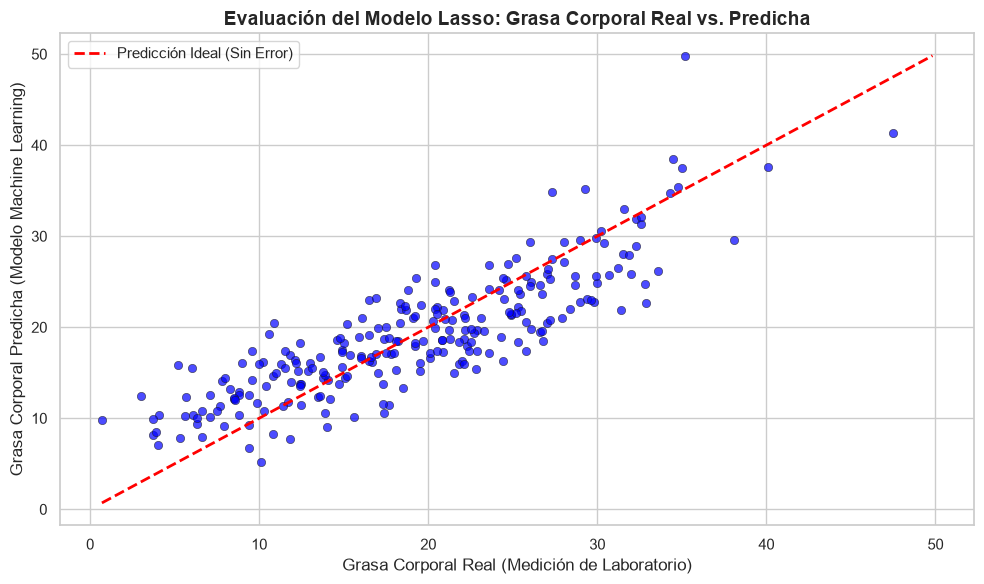

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generar predicciones con el modelo final
predicciones = modelo_final.predict(X)

# 2. Configurar el gráfico
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y, y=predicciones, alpha=0.7, color='blue', edgecolor='k')

# 3. Dibujar Línea de predicción perfecta (y = x)
min_val = min(min(y), min(predicciones))
max_val = max(max(y), max(predicciones))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Ideal (Sin Error)')

# 4. Etiquetas y presentación
plt.title('Evaluación del Modelo Lasso: Grasa Corporal Real vs. Predicha', fontsize=14, fontweight='bold')
plt.xlabel('Grasa Corporal Real (Medición de Laboratorio)', fontsize=12)
plt.ylabel('Grasa Corporal Predicha (Modelo Machine Learning)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
--- Iniciando el Entrenamiento de la Red Neuronal ---
Epoch 1/200



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\Jonatan\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 47ms/step - loss: 467.9359 - mae: 19.9086 - val_loss: 389.4052 - val_mae: 17.9133
Epoch 2/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 458.8306 - mae: 19.7000 - val_loss: 382.7667 - val_mae: 17.7520
Epoch 3/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 451.8749 - mae: 19.5495 - val_loss: 376.2967 - val_mae: 17.5934
Epoch 4/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 444.1435 - mae: 19.3955 - val_loss: 369.7091 - val_mae: 17.4318
Epoch 5/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 437.3554 - mae: 19.2374 - val_loss: 363.0381 - val_mae: 17.2676
Epoch 6/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 428.6780 - mae: 19.0369 - val_loss: 356.2389 - val_mae: 17.1000
Epoch 7/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 423.5163 - mae: 18.9132 - val_loss: 348.9214 - val_mae: 16.9197
Epoch 8/200
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 413.2638 - mae: 18.6822 - val_loss: 340.9778 - val_mae: 16.7230
Epoch 9/200
5/5 ━━━━━━━━━━━━━━━━━━━━

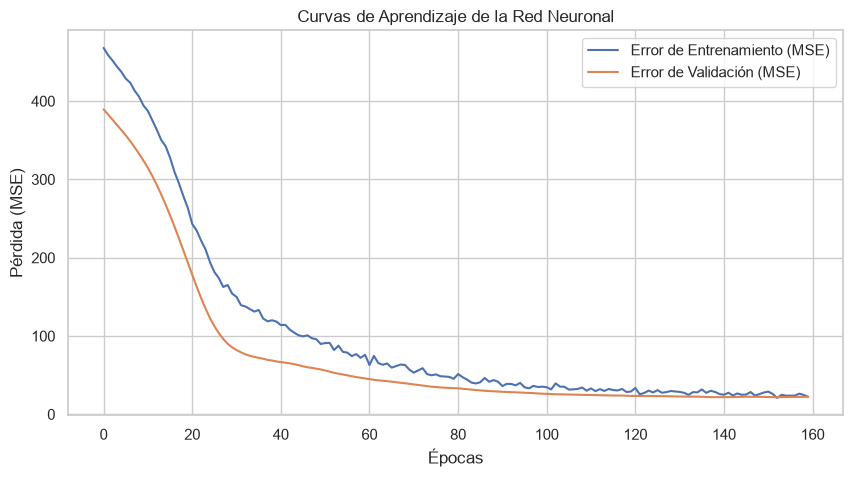

In [22]:
%pip install tensorflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Recuperar datos limpios
df = pd.read_csv(r'bodyfat.xls')
df_clean = df[(df['Height'] > 30) & (df['BodyFat'] > 0)].copy()
df_clean = df_clean.drop(columns=['Density'], errors='ignore')

X = df_clean.drop(columns=['BodyFat'])
y = df_clean['BodyFat']

# 2. Train/Test Split (80% Entrenamiento - 20% Prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Escalado: ¡Crucial para Redes Neuronales!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Construir Arquitectura de la Red Neuronal (DNN)
# Siguiendo la bibliografía de Keras de la diplomatura
modelo_dnn = Sequential([
    # Capa de entrada y primera capa oculta (32 neuronas, función ReLU)
    Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    
    # Capa de Regularización (Dropout) para apagar 20% de neuronas y evitar Overfitting
    Dropout(0.2),
    
    # Segunda capa oculta (16 neuronas, función ReLU)
    Dense(16, activation='relu'),
    
    # Capa de Salida (1 neurona, activación lineal para Regresión)
    Dense(1) 
])

# 5. Compilar el modelo
# Optimizador Adam y MSE (Error Cuadrático Medio) para el cálculo de la pérdida
modelo_dnn.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 6. Freno de Emergencia (Early Stopping)
# Si el modelo deja de mejorar en los datos de validación por 20 épocas, frena para no sobreajustar.
early_stop = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

# 7. Entrenar la Red
print("--- Iniciando el Entrenamiento de la Red Neuronal ---")
historia = modelo_dnn.fit(X_train_scaled, y_train, 
                          epochs=200, 
                          validation_split=0.2, # Separa un pedacito extra para validar en cada época
                          callbacks=[early_stop], 
                          verbose=1)

# 8. Evaluación con el conjunto de Test
predicciones_dnn = modelo_dnn.predict(X_test_scaled).flatten()

mae_dnn = mean_absolute_error(y_test, predicciones_dnn)
rmse_dnn = np.sqrt(mean_squared_error(y_test, predicciones_dnn))

print("\n--- RESULTADOS FINALES RED NEURONAL ---")
print(f"MAE de la Red Neuronal: {mae_dnn:.2f} % de grasa")
print(f"RMSE de la Red Neuronal: {rmse_dnn:.2f} % de grasa")

# 9. Graficar las curvas de aprendizaje (Loss)
plt.figure(figsize=(10, 5))
plt.plot(historia.history['loss'], label='Error de Entrenamiento (MSE)')
plt.plot(historia.history['val_loss'], label='Error de Validación (MSE)')
plt.title('Curvas de Aprendizaje de la Red Neuronal')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.legend()
plt.show()